In [1]:
# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for plotting and visualization
import matplotlib.pyplot as plt

# Import the handwritten digits dataset from Scikit-learn
from sklearn.datasets import load_digits

# Import function for splitting data into training and testing sets
from sklearn.model_selection import train_test_split

# Import Support Vector Classifier (SVM)
from sklearn.svm import SVC

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
# Load the built-in handwritten digits dataset
digits = load_digits()

# Store the input features (pixel values)
X = digits.data

# Store the target labels (actual digits: 0 to 9)
y = digits.target

print("Dataset loaded successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Dataset loaded successfully!
X shape: (1797, 64)
y shape: (1797,)


In [3]:
# Display the number of samples and features
print("Number of images:", X.shape[0])
print("Number of features:", X.shape[1])

# Display the different digit classes
print("Classes:", np.unique(y))

Number of images: 1797
Number of features: 64
Classes: [0 1 2 3 4 5 6 7 8 9]


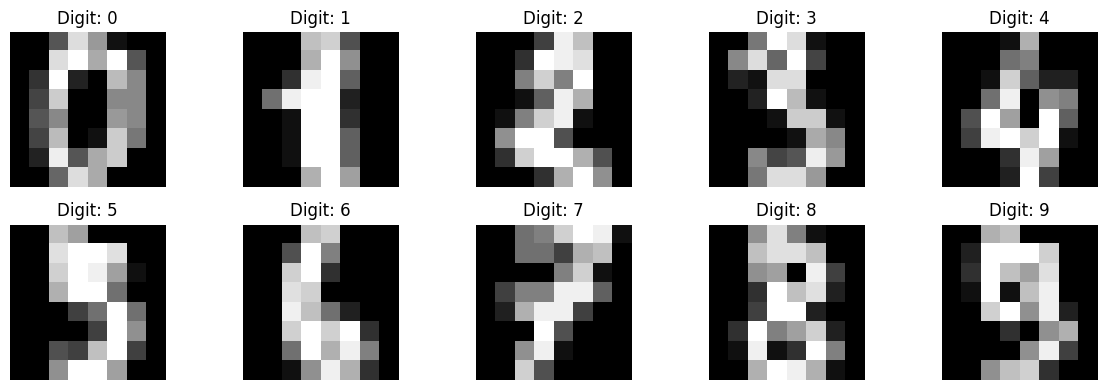

In [5]:
# Create a figure containing 10 sample digit images
plt.figure(figsize=(12, 4))

for i in range(10):
    # Create a subplot for each digit
    plt.subplot(2, 5, i + 1)

    # Display the image using its original 8x8 pixel representation
    plt.imshow(digits.images[i], cmap="gray")

    # Display the actual digit as the title
    plt.title(f"Digit: {digits.target[i]}")

    # Hide the axis for a cleaner visualization
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Split the dataset into training and testing sets.
#
# test_size=0.20 means:
# 80% of the data will be used for training
# 20% of the data will be used for testing
#
# stratify=y ensures that all digit classes are represented
# proportionally in both training and testing sets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1437
Testing samples: 360


In [7]:
# Create an SVM classifier using the RBF (Radial Basis Function) kernel.
#
# C controls the penalty for misclassification.
# gamma='scale' automatically determines a suitable gamma value.
#
# RBF is useful because handwritten digits are not linearly separable.

svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

print("SVM model created successfully!")

SVM model created successfully!


In [8]:
# Train the SVM model using the training data.
# The model learns the relationship between pixel values and digit labels.

svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [9]:
# Use the trained model to predict digits for the test dataset.

y_pred = svm_model.predict(X_test)

# Display the first 10 predictions
print("First 10 predictions:")
print(y_pred[:10])

# Display the corresponding actual values
print("\nActual values:")
print(y_test[:10])

First 10 predictions:
[5 2 8 1 7 2 6 2 6 5]

Actual values:
[5 2 8 1 7 2 6 2 6 5]


In [10]:
# Calculate the percentage of correctly classified test samples.

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 99.44%


In [11]:
# Count the number of correctly classified samples
correct_predictions = np.sum(y_pred == y_test)

# Count the number of incorrectly classified samples
incorrect_predictions = np.sum(y_pred != y_test)

print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)
print("Total test samples:", len(y_test))

Correct predictions: 358
Incorrect predictions: 2
Total test samples: 360


In [12]:
# Generate a detailed classification report.
#
# It provides:
# Precision → how many predicted samples were actually correct
# Recall    → how many actual samples were correctly identified
# F1-score  → balance between precision and recall

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      1.00      0.99        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       1.00      0.97      0.99        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



Confusion Matrix:
[[36  0  0  0  0  0  0  0  0  0]
 [ 0 36  0  0  0  0  0  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 36  0  0  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  1  0  0  0  0  0  0 34  0]
 [ 0  0  0  0  0  0  0  1  0 35]]


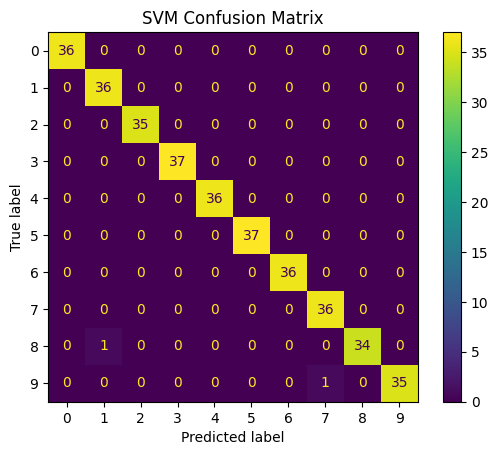

In [14]:
# Generate the confusion matrix.
#
# Rows represent the actual digit.
# Columns represent the predicted digit.

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)
# Create a visual representation of the confusion matrix.

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

# Plot the confusion matrix
disp.plot()

plt.title("SVM Confusion Matrix")
plt.show()

In [15]:
# Find the positions where the prediction is different
# from the actual label.

misclassified_indices = np.where(y_pred != y_test)[0]

print("Number of misclassified images:",
      len(misclassified_indices))

Number of misclassified images: 2


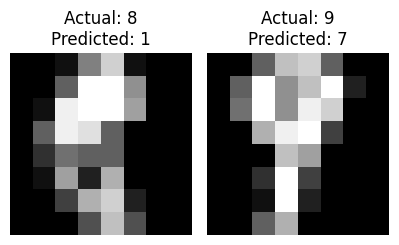

In [16]:
# Display the images that the SVM classified incorrectly.

plt.figure(figsize=(10, 5))

for i, index in enumerate(misclassified_indices[:10]):

    # Create a subplot
    plt.subplot(2, 5, i + 1)

    # Get the corresponding test image
    image = X_test[index].reshape(8, 8)

    # Display the image
    plt.imshow(image, cmap="gray")

    # Display actual and predicted values
    plt.title(
        f"Actual: {y_test[index]}\n"
        f"Predicted: {y_pred[index]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()